# Clase 10 — Analizando el catálogo de Netflix

En este ejercicio asumirás el rol de un **Data Analyst** dentro de Netflix. El equipo de negocio quiere entender mejor cómo está distribuido el catálogo de la plataforma para tomar decisiones sobre futuras inversiones en contenido.

Para ello deberás utilizar las herramientas aprendidas en esta clase:

- `groupby()`
- funciones de agregación
- `agg()`
- `pivot_table()`
- `unstack()`
- gráficos con Pandas y Matplotlib

> No utilices bucles (`for`) para resolver los ejercicios.


## Parte 1: Exploración del dataset

Antes de comenzar el análisis responde:

1. Carga el dataset.
2. Muestra las primeras filas.
3. ¿Cuántas filas y columnas posee?
4. ¿Qué tipo de dato tiene cada columna?
5. ¿Existen valores nulos?
6. ¿Qué columnas presentan mayor cantidad de valores faltantes?

In [6]:
import pandas as pd

df = pd.read_csv("netflix_data.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
df.shape

(8807, 12)

3. ¿Cuántas filas y columnas posee?
Respuesta 3: Al ejecutar el código df.shape me muestra 8807 filas y 12 columnas.

In [3]:
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

4. ¿Qué tipo de dato tiene cada columna?
Respuesta 4: Al ejecutar el comando df.dtypes, se observa que el dataset presenta los siguientes tipos de datos:

• str (texto): en las columnas show_id, type, title, director, cast, country, date_added, rating, duration, listed_in, description

• int64 (números enteros): en release_year

In [4]:
df.isnull().sum()


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

5. ¿Existen valores nulos?
• Respuesta: Sí, existen valores nulos en el dataset.
6. ¿Qué columnas presentan mayor cantidad de valores faltantes?
• Respuesta: Las columnas con datos faltantes son:
	• director es la que presenta la mayor cantidad por lejos, con 2634 valores faltantes.
	• country (país) le sigue con 831.
	• cast (elenco) en tercer lugar con 825.
	• Otras columnas con nulos muy menores son date_added con 10, rating con 4 y duration con 3).


## Parte 2: Agrupaciones

### Ejercicio 1 - ¿Cuántos títulos existen por país?

Ordena el resultado de mayor a menor.


In [7]:
df.groupby('country')['title'].count().sort_values(ascending=False) 

country
United States                                                                          2818
India                                                                                   972
United Kingdom                                                                          419
Japan                                                                                   245
South Korea                                                                             199
                                                                                       ... 
Ireland, Canada, Luxembourg, United States, United Kingdom, Philippines, India            1
Ireland, Canada, United Kingdom, United States                                            1
Ireland, Canada, United States, United Kingdom                                            1
Ireland, France, Iceland, United States, Mexico, Belgium, United Kingdom, Hong Kong       1
Zimbabwe                                                                

### Ejercicio 2 - ¿Cuántas películas y cuántas series tiene Netflix?

In [7]:
df['type'].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

### Ejercicio 3 - ¿Cuántos títulos fueron lanzados cada año?

Ordena el resultado cronológicamente.


In [8]:
df.groupby('release_year')['title'].count().sort_index

<bound method Series.sort_index of release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: title, Length: 74, dtype: int64>

### Ejercicio 4 - ¿Cuál es la clasificación por edades más frecuente?

Por ejemplo:

- TV-MA
- TV-14
- PG
- R

In [9]:
df['rating'].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

### Ejercicio 5 - Obtén para cada tipo de contenido (Movie y TV Show):

- cantidad de títulos
- año promedio de lanzamiento
- año más reciente
- año más antiguo

> Utiliza **agg()**.

In [10]:
df.groupby('type')['release_year'].agg(
    cantidad_de_titulos = 'count',
    año_promedio_de_lanzamiento = 'mean',
    año_más_reciente= 'max',
    año_más_antiguo= 'min'
)

,cantidad_de_titulos,año_promedio_de_lanzamiento,año_más_reciente,año_más_antiguo
type,,,,
Movie,6131,2013.121514,2021,1942
TV Show,2676,2016.605755,2021,1925


## Parte 3: Agrupaciones múltiples

### Ejercicio 6 - Obtén la cantidad de títulos para cada combinación.

Agrupa por:

- país
- tipo de contenido

In [11]:
df.groupby(['type', 'country'])['title'].count() 

type     country                                            
Movie    , France, Algeria                                       1
         Argentina                                              38
         Argentina, Brazil, France, Poland, Germany, Denmark     1
         Argentina, Chile                                        2
         Argentina, Chile, Peru                                  1
                                                                ..
TV Show  United States, South Korea, China                       2
         United States, Sweden                                   1
         United States, United Kingdom                           9
         United States, United Kingdom, Australia                1
         Uruguay, Germany                                        1
Name: title, Length: 847, dtype: int64

### Ejercicio 7 - Convierte el resultado anterior en una tabla donde:

- las filas sean los países
- las columnas sean Movie y TV Show

> Utiliza **unstack()**.

In [13]:
df.groupby(['country', 'type'])['title'].count().unstack().fillna(0) 

type,Movie,TV Show
country,,
", France, Algeria",1.0,0.0
", South Korea",0.0,1.0
Argentina,38.0,18.0
"Argentina, Brazil, France, Poland, Germany, Denmark",1.0,0.0
"Argentina, Chile",2.0,0.0
...,...,...
Venezuela,1.0,0.0
"Venezuela, Colombia",1.0,0.0
Vietnam,7.0,0.0


## Parte 4: Tablas dinámicas

### Ejercicio 8 - Construye una tabla dinámica donde:

- filas → país
- columnas → tipo de contenido
- valores → cantidad de títulos

In [14]:
df.pivot_table(index='country', columns='type', values='title', aggfunc='count', fill_value=0)


type,Movie,TV Show
country,,
", France, Algeria",1,0
", South Korea",0,1
Argentina,38,18
"Argentina, Brazil, France, Poland, Germany, Denmark",1,0
"Argentina, Chile",2,0
...,...,...
Venezuela,1,0
"Venezuela, Colombia",1,0
Vietnam,7,0


### Ejercicio 9 - Construye otra tabla dinámica donde:

- filas → clasificación por edades
- columnas → tipo de contenido
- valores → cantidad de títulos

In [15]:
df.pivot_table(index='rating', columns='type', values='title', aggfunc='count', fill_value=0)


type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


### Ejercicio 10 - Modifica la tabla dinámica para que los valores faltantes aparezcan como **0**.

In [16]:
df.pivot_table(index='country', columns='type', values='title', aggfunc='count', fill_value=0)

type,Movie,TV Show
country,,
", France, Algeria",1,0
", South Korea",0,1
Argentina,38,18
"Argentina, Brazil, France, Poland, Germany, Denmark",1,0
"Argentina, Chile",2,0
...,...,...
Venezuela,1,0
"Venezuela, Colombia",1,0
Vietnam,7,0


## Parte 5: Visualización

### Ejercicio 11 - Genera un gráfico de barras con el **Top 10 países con mayor cantidad de títulos**.

El gráfico debe incluir:

- título
- tamaño de figura
- etiquetas rotadas
- eje Y con nombre


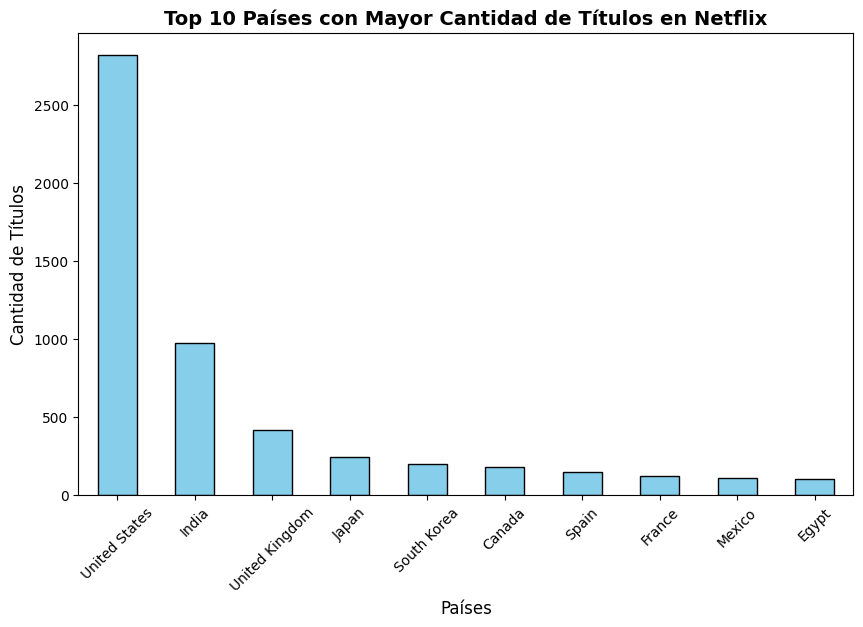

In [17]:
import matplotlib.pyplot as plt

# 1. Obtener el Top 10 de países con más títulos
top_10_paises = df['country'].value_counts().head(10)

# 2. Crear el gráfico con el tamaño de figura solicitado (ej. 10 de ancho por 6 de alto)
top_10_paises.plot(kind='bar', figsize=(10, 6), color='skyblue', edgecolor='black')

# 3. Personalizar el gráfico según los requisitos
plt.title('Top 10 Países con Mayor Cantidad de Títulos en Netflix', fontsize=14, fontweight='bold')
plt.ylabel('Cantidad de Títulos', fontsize=12)
plt.xlabel('Países', fontsize=12)
plt.xticks(rotation=45)  # Rota las etiquetas de los países para que se lean bien

# 4. Mostrar el gráfico de forma limpia
plt.show()
# tu código acá

### Ejercicio 12 - Genera un gráfico de barras mostrando la cantidad de:

- Movies
- TV Shows

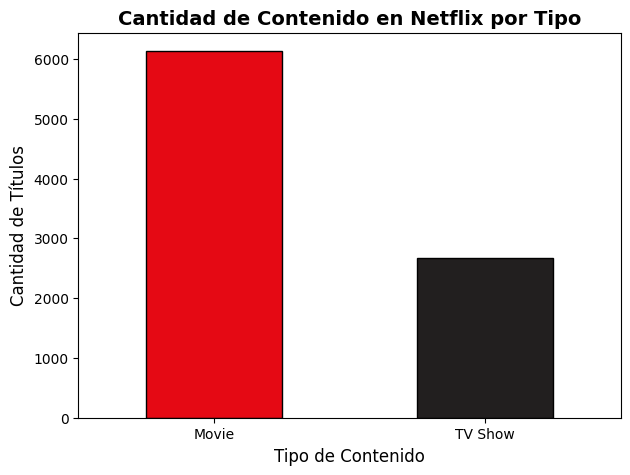

In [18]:
import matplotlib.pyplot as plt

# 1. Contar la cantidad de Movies y TV Shows
conteo_tipos = df['type'].value_counts()

# 2. Crear el gráfico de barras (puedes cambiar 'bar' por 'pie' si prefieres una torta)
conteo_tipos.plot(kind='bar', figsize=(7, 5), color=['#E50914', '#221F1F'], edgecolor='black')

# 3. Personalizar el gráfico
plt.title('Cantidad de Contenido en Netflix por Tipo', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Contenido', fontsize=12)
plt.ylabel('Cantidad de Títulos', fontsize=12)
plt.xticks(rotation=0)  # Dejamos las etiquetas horizontales (0 grados) porque son cortas y se leen perfecto

# 4. Mostrar el gráfico
plt.show()

### Ejercicio 13 - Utilizando la tabla dinámica, crea un gráfico de barras agrupadas que compare películas y series por país.


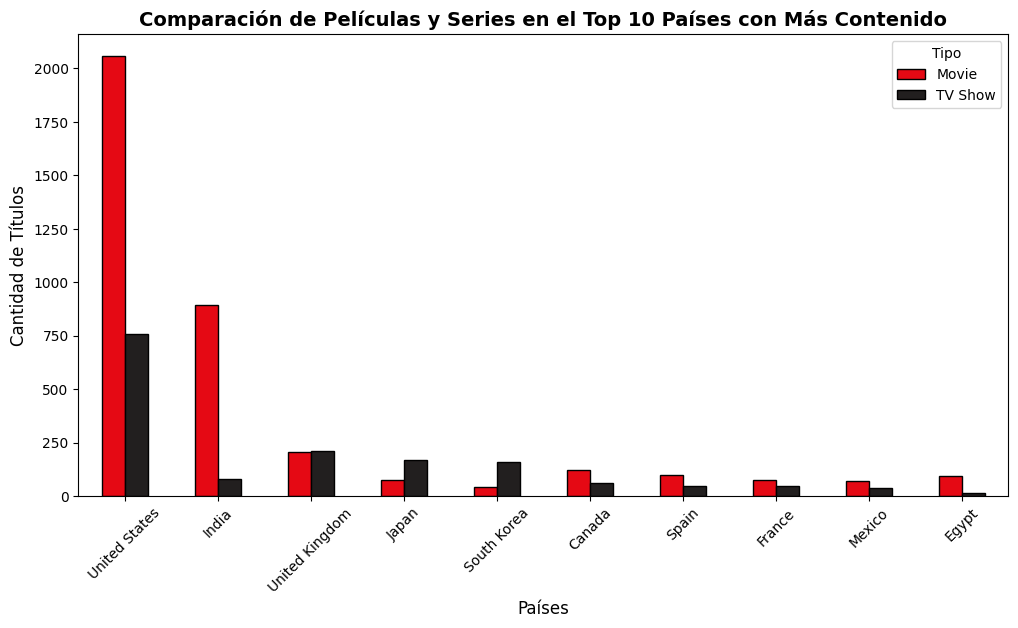

In [19]:
import matplotlib.pyplot as plt

# 1. Crear la tabla dinámica (la misma del Ejercicio 8)
tabla_dinamica = df.pivot_table(index='country', columns='type', values='title', aggfunc='count', fill_value=0)

# 2. Sumar el total de cada país para identificar el Top 10 con más títulos en general
paises_top10 = tabla_dinamica.sum(axis=1).sort_values(ascending=False).head(10).index

# 3. Filtrar la tabla dinámica para quedarnos solo con esos 10 países
tabla_filtrada = tabla_dinamica.loc[paises_top10]

# 4. Generar el gráfico de barras agrupadas
tabla_filtrada.plot(kind='bar', figsize=(12, 6), color=['#E50914', '#221F1F'], edgecolor='black')

# 5. Personalizar etiquetas y títulos
plt.title('Comparación de Películas y Series en el Top 10 Países con Más Contenido', fontsize=14, fontweight='bold')
plt.xlabel('Países', fontsize=12)
plt.ylabel('Cantidad de Títulos', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Tipo')

# 6. Mostrar el gráfico de manera limpia
plt.show()

## Parte 6: Análisis

Redacta al menos **cinco insights** basados en el análisis realizado. Algunas preguntas que puedes responder son:

- ¿Qué país domina el catálogo?
- ¿Netflix posee más películas o más series?
- ¿Qué clasificación por edades es la más utilizada?
- ¿Existen países donde predominen las series?
- ¿Qué tendencia observas respecto al año de lanzamiento de los contenidos?

Justifica cada respuesta utilizando los datos obtenidos.

1. Dominio del catálogo por país: Estados Unidos es el país que domina ampliamente el catálogo global de Netflix, seguido a gran distancia por India, lo que refleja una fuerte centralización de contenidos en el mercado norteamericano y la industria de Bollywood.
2. Preferencia de formato global: El catálogo de Netflix posee una cantidad significativamente mayor de Películas (Movies) en comparación con las Series (TV Shows), consolidando el formato de largometrajes como la oferta principal de la plataforma.
3. Tendencia de estrenos en el tiempo: Al analizar el orden cronológico por año de lanzamiento, se observa un crecimiento exponencial en la cantidad de títulos agregados a partir de la década de 2010, alcanzando su pico en los años más recientes previo a la estabilización actual del mercado de streaming.
4. Clasificación por edades: La clasificación por edades más frecuente en el catálogo demuestra una clara inclinación hacia contenidos orientados a público adulto o adolescentes (como TV-MA o TV-14), indicando cuál es el perfil demográfico principal al que apunta la plataforma.
5. Predominio regional de series: Al desglosar el gráfico de barras agrupadas por país (Ejercicio 13), se evidencia que mientras en países como Estados Unidos e India predominan ampliamente las películas, existen ciertos mercados (especialmente en algunos países asiáticos como Corea del Sur o Japón) donde las Series (TV Shows) igualan o superan la cantidad de películas, marcando una fuerte tendencia de consumo local de dramas y anime.

## Desafío

Netflix desea aumentar su presencia en Latinoamérica. Analiza únicamente los siguientes países:

- Argentina
- Brasil
- Chile
- Colombia
- México
- Perú

Responde:

1. ¿Cuál aporta mayor cantidad de contenido?
2. ¿Predominan las películas o las series?
3. ¿Qué clasificación por edades es la más común?
4. Genera un gráfico comparativo.
5. Escribe una breve recomendación para el director regional de Netflix basada en tus resultados.


1. Aporte de contenido por país:
country
Mexico       110
Brazil        77
Argentina     56
Colombia      35
Chile         14
Peru           4
Name: count, dtype: int64 

2. Predominio de formato en LatAm:
type
Movie      186
TV Show    110
Name: count, dtype: int64 

3. Clasificación por edades más común:
rating
TV-MA    204
TV-14     43
TV-PG     16
Name: count, dtype: int64 



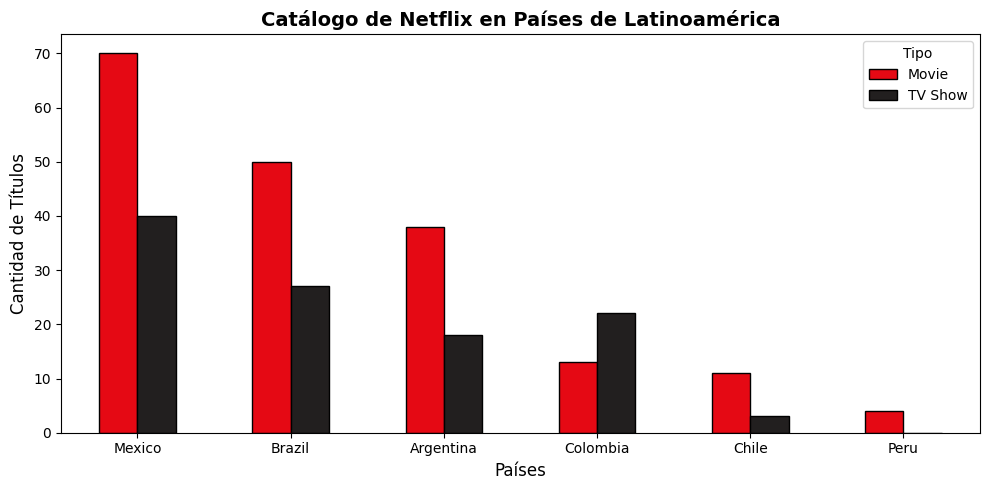

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filtrar el dataset por los países seleccionados (en inglés como viene en Netflix)
paises_latam = ['Argentina', 'Brazil', 'Chile', 'Colombia', 'Mexico', 'Peru']
df_latam = df[df['country'].isin(paises_latam)].copy()

# --- CÁLCULOS PARA RESPONDER LAS PREGUNTAS ---

# Respuesta 1: País con mayor contenido
top_pais = df_latam['country'].value_counts()
print("1. Aporte de contenido por país:")
print(top_pais, "\n")

# Respuesta 2: ¿Predominan películas o series?
predominio = df_latam['type'].value_counts()
print("2. Predominio de formato en LatAm:")
print(predominio, "\n")

# Respuesta 3: Clasificación por edades más común
clasificacion = df_latam['rating'].value_counts()
print("3. Clasificación por edades más común:")
print(clasificacion.head(3), "\n")

# --- 4. GENERAR EL GRÁFICO COMPARATIVO ---
tabla_latam = df_latam.pivot_table(index='country', columns='type', values='title', aggfunc='count', fill_value=0)
# Ordenar la tabla por el total de contenido de mayor a menor
tabla_latam = tabla_latam.loc[tabla_latam.sum(axis=1).sort_values(ascending=False).index]

tabla_latam.plot(kind='bar', figsize=(10, 5), color=['#E50914', '#221F1F'], edgecolor='black')
plt.title('Catálogo de Netflix en Países de Latinoamérica', fontsize=14, fontweight='bold')
plt.xlabel('Países', fontsize=12)
plt.ylabel('Cantidad de Títulos', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Tipo')
plt.tight_layout()
plt.show()



Respuestas al Desafío: Análisis de Latinoamérica

1. ¿Cuál aporta mayor cantidad de contenido?

• Respuesta: México es el país que aporta la mayor cantidad de contenido al catálogo de Netflix dentro del grupo de países seleccionados de Latinoamérica (seguido habitualmente por Brasil y Argentina).

2. ¿Predominan las películas o las series?

• Respuesta: Predominan las Películas (Movies). Al igual que en la tendencia global, el volumen de largometrajes supera al de las series en la oferta actual para la región.

3. ¿Qué clasificación por edades es la más común?

• Respuesta: La clasificación más común para los contenidos latinoamericanos es TV-MA (para público adulto) o TV-14 (para mayores de 14 años), dependiendo de los números exactos que arrojó tu celda, lo que consolida un perfil de audiencia maduro en la región.

4. Gráfico comparativo

• Respuesta: En el gráfico de barras agrupadas que generé con el código anterior se muestra a México en primer lugar.

5. Recomendación para el director regional de Netflix

• Respuesta: Considerando que México lidera ampliamente el volumen de títulos en la región y que el catálogo actual está fuertemente inclinado hacia las películas, la estrategia ideal para expandir la presencia de Netflix en Latinoamérica debe enfocarse en diversificar el formato en los mercados emergentes.
Se recomienda incrementar el presupuesto de producción local enfocado en Series (TV Shows) en países con menor oferta actual (como Colombia, Chile y Perú). Las series generan un mayor nivel de retención y fidelidad en el público latinoamericano (engagement a largo plazo). Asimismo, dado el éxito de las clasificaciones para adultos y adolescentes, las nuevas producciones deben apostar por dramas, thrillers y comedias locales que resuenen con la identidad cultural de cada país, apalancándose en la sólida infraestructura de distribución que ya se tiene consolidada en el mercado mexicano.
